# 02 — Exploratory Analysis

Explore the survey ratings and make charts from the data.

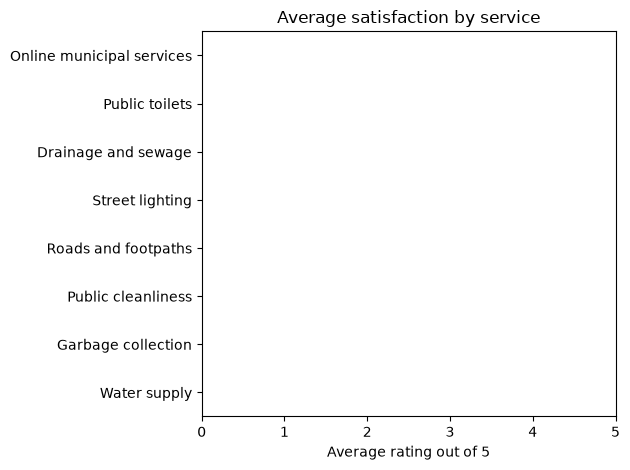

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Read the cleaned survey data.
project_folder = Path.cwd().parent
clean_file = project_folder / 'data' / 'processed' / 'responses_clean.csv'
data = pd.read_csv(clean_file)

# Define the service rating columns.
rating_columns = {
    'Water supply': '5. How satisfied are you with the regularity of water supply?',
    'Garbage collection': '6. How satisfied are you with garbage collection?',
    'Public cleanliness': '7. How satisfied are you with the cleanliness of public areas?',
    'Roads and footpaths': '8. How satisfied are you with the condition of roads and footpaths?',
    'Street lighting': '9. How satisfied are you with street lighting in your area?',
    'Drainage and sewage': '10. How satisfied are you with drainage and sewage services?',
    'Public toilets': '11. How satisfied are you with the availability and cleanliness of public toilets?',
    'Online municipal services': '12. How satisfied are you with online municipal services or complaint systems?',
}

# Convert each rating answer to a number.
for service, column in rating_columns.items():
    data[service] = pd.to_numeric(data[column].astype('string').str.extract(r'^\\s*(\\d+)')[0], errors='coerce')

# Calculate the average rating for each service.
average_ratings = data[list(rating_columns.keys())].mean().sort_values()
average_ratings.plot(kind='barh', title='Average satisfaction by service', xlim=(0, 5))
plt.xlabel('Average rating out of 5')
plt.tight_layout()
plt.show()